In [1]:
import sys
import platform
import importlib.util
from pathlib import Path

import pandas as pd

# Project root detect karo
ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA_PATH = (
    ROOT
    / "data"
    / "processed"
    / "bitext"
    / "bitext_customer_support_clean.csv"
)

print("=== SYSTEM INFORMATION ===")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Project root:", ROOT)

# Check required libraries without installing anything
required_packages = [
    "torch",
    "transformers",
    "datasets",
    "accelerate",
    "evaluate",
]

print("\n=== PACKAGE AVAILABILITY ===")

for package in required_packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'INSTALLED' if available else 'NOT INSTALLED'}")

# PyTorch and GPU information, if available
if importlib.util.find_spec("torch") is not None:
    import torch

    print("\n=== PYTORCH / HARDWARE ===")
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
    else:
        print("Training will use CPU unless another supported device is configured.")

# Verify the cleaned Bitext dataset
print("\n=== DATASET CHECK ===")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df_dl = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_dl.shape)
print("Columns:", df_dl.columns.tolist())
print("Intent classes:", df_dl["intent"].nunique())
print("Category classes:", df_dl["category"].nunique())
print("Missing instruction values:", df_dl["instruction"].isna().sum())
print("Missing intent values:", df_dl["intent"].isna().sum())

display(df_dl[["instruction", "intent", "category"]].head())

=== SYSTEM INFORMATION ===
Python: 3.11.0
Platform: Windows-10-10.0.26300-SP0
Project root: d:\Data scientist\AI Customer Support Intelligence

=== PACKAGE AVAILABILITY ===
torch: INSTALLED
transformers: INSTALLED
datasets: INSTALLED
accelerate: INSTALLED
evaluate: NOT INSTALLED

=== PYTORCH / HARDWARE ===
PyTorch version: 2.14.1+cpu
CUDA available: False
Training will use CPU unless another supported device is configured.

=== DATASET CHECK ===
Dataset shape: (26872, 5)
Columns: ['flags', 'instruction', 'category', 'intent', 'response']
Intent classes: 27
Category classes: 11
Missing instruction values: 0
Missing intent values: 0


,instruction,intent,category
0,question about cancelling order {{Order Number}},cancel_order,ORDER
1,i have a question about cancelling oorder {{Or...,cancel_order,ORDER
2,i need help cancelling puchase {{Order Number}},cancel_order,ORDER
3,I need to cancel purchase {{Order Number}},cancel_order,ORDER
4,"I cannot afford this order, cancel purchase {{...",cancel_order,ORDER


In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Cleaned dataset ki working copy
dl_df = df_dl.copy()

dl_df["instruction"] = (
    dl_df["instruction"].astype(str).str.strip()
)

dl_df["intent"] = dl_df["intent"].astype(str).str.strip()
dl_df["category"] = dl_df["category"].astype(str).str.strip()

# Same query ko identify karne ke liye normalization
dl_df["instruction_normalized"] = (
    dl_df["instruction"].str.lower().str.strip()
)

# Verify karo ki same normalized query ka label consistent hai
intent_per_query = (
    dl_df.groupby("instruction_normalized")["intent"].nunique()
)

category_per_query = (
    dl_df.groupby("instruction_normalized")["category"].nunique()
)

assert intent_per_query.max() == 1, (
    "Repeated query groups contain conflicting intents."
)

assert category_per_query.max() == 1, (
    "Repeated query groups contain conflicting categories."
)

# Unique query groups ko split karo
unique_queries = (
    dl_df.groupby("instruction_normalized", as_index=False)
    .agg(
        intent=("intent", "first"),
        category=("category", "first"),
    )
)

train_groups, val_groups = train_test_split(
    unique_queries,
    test_size=0.20,
    random_state=42,
    stratify=unique_queries["intent"],
)

train_query_set = set(train_groups["instruction_normalized"])
val_query_set = set(val_groups["instruction_normalized"])

# Har query ki saari copies usi split mein rahengi
dl_train_df = dl_df[
    dl_df["instruction_normalized"].isin(train_query_set)
].copy()

dl_val_df = dl_df[
    dl_df["instruction_normalized"].isin(val_query_set)
].copy()

# Leakage check
query_overlap = (
    set(dl_train_df["instruction_normalized"])
    & set(dl_val_df["instruction_normalized"])
)

assert len(query_overlap) == 0, "Query leakage detected!"

# Intent labels ko numeric IDs mein encode karo
label_encoder_dl = LabelEncoder()
label_encoder_dl.fit(dl_df["intent"])

dl_train_df["label"] = label_encoder_dl.transform(
    dl_train_df["intent"]
)

dl_val_df["label"] = label_encoder_dl.transform(
    dl_val_df["intent"]
)

# Model config ke liye mappings
label2id = {
    label: index
    for index, label in enumerate(label_encoder_dl.classes_)
}

id2label = {
    index: label
    for label, index in label2id.items()
}

print("Train rows:", f"{len(dl_train_df):,}")
print("Validation rows:", f"{len(dl_val_df):,}")
print("Training unique queries:", dl_train_df["instruction_normalized"].nunique())
print("Validation unique queries:", dl_val_df["instruction_normalized"].nunique())
print("Query overlap:", len(query_overlap))
print("Intent classes:", len(label_encoder_dl.classes_))

print("\nTraining label distribution:")
display(dl_train_df["intent"].value_counts().sort_index())

print("\nValidation label distribution:")
display(dl_val_df["intent"].value_counts().sort_index())

print("\nSample training records:")
display(dl_train_df[["instruction", "intent", "label"]].head())

Train rows: 21,525
Validation rows: 5,347
Training unique queries: 19496
Validation unique queries: 4875
Query overlap: 0
Intent classes: 27

Training label distribution:


intent
cancel_order                790
change_order                799
change_shipping_address     780
check_cancellation_fee      758
check_invoice               803
check_payment_methods       799
check_refund_policy         800
complaint                   800
contact_customer_service    799
contact_human_agent         797
create_account              795
delete_account              798
delivery_options            828
delivery_period             801
edit_account                816
get_invoice                 792
get_refund                  786
newsletter_subscription     799
payment_issue               800
place_order                 799
recover_password            797
registration_problems       799
review                      797
set_up_shipping_address     797
switch_account              797
track_order                 799
track_refund                800
Name: count, dtype: int64


Validation label distribution:


intent
cancel_order                208
change_order                198
change_shipping_address     193
check_cancellation_fee      192
check_invoice               197
check_payment_methods       200
check_refund_policy         197
complaint                   200
contact_customer_service    201
contact_human_agent         202
create_account              202
delete_account              197
delivery_options            167
delivery_period             198
edit_account                184
get_invoice                 207
get_refund                  211
newsletter_subscription     200
payment_issue               199
place_order                 199
recover_password            198
registration_problems       200
review                      200
set_up_shipping_address     200
switch_account              203
track_order                 196
track_refund                198
Name: count, dtype: int64


Sample training records:


,instruction,intent,label
0,question about cancelling order {{Order Number}},cancel_order,0
1,i have a question about cancelling oorder {{Or...,cancel_order,0
2,i need help cancelling puchase {{Order Number}},cancel_order,0
3,I need to cancel purchase {{Order Number}},cancel_order,0
4,"I cannot afford this order, cancel purchase {{...",cancel_order,0


In [5]:
import transformers
import torch

from transformers import BertTokenizerLegacy

MODEL_NAME = "prajjwal1/bert-tiny"

print("Transformers version:", transformers.__version__)
print("Loading legacy BERT tokenizer...")

tokenizer = BertTokenizerLegacy.from_pretrained(
    MODEL_NAME,
    do_lower_case=True,
)

# Test tokenization
sample_text = "I want to cancel my order"

encoded = tokenizer(
    sample_text,
    truncation=True,
    max_length=64,
    return_tensors="pt",
)

print("\nTokenizer loaded successfully!")
print("Tokenizer class:", type(tokenizer).__name__)
print("Vocabulary size:", tokenizer.vocab_size)
print("Sample text:", sample_text)
print("Token IDs:", encoded["input_ids"].tolist())
print("Attention mask:", encoded["attention_mask"].tolist())
print("Tokenized length:", encoded["input_ids"].shape[1])

Transformers version: 5.20.2
Loading legacy BERT tokenizer...


vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]


Tokenizer loaded successfully!
Tokenizer class: BertTokenizerLegacy
Vocabulary size: 30522
Sample text: I want to cancel my order
Token IDs: [[101, 1045, 2215, 2000, 17542, 2026, 2344, 102]]
Attention mask: [[1, 1, 1, 1, 1, 1, 1, 1]]
Tokenized length: 8


In [6]:
import torch
import transformers

from transformers import BertForSequenceClassification

MODEL_NAME = "prajjwal1/bert-tiny"

# Label mappings Cell 2 se use honge
num_labels = len(label_encoder_dl.classes_)

label2id = {
    str(label): int(index)
    for index, label in enumerate(label_encoder_dl.classes_)
}

id2label = {
    int(index): str(label)
    for index, label in enumerate(label_encoder_dl.classes_)
}

print("Loading BERT-Tiny classification model...")

model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    label2id=label2id,
    id2label=id2label,
    problem_type="single_label_classification",
)

# CPU/GPU device select karo
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nModel loaded successfully!")
print("Model:", MODEL_NAME)
print("Transformers:", transformers.__version__)
print("Device:", device)
print("Intent classes:", model.config.num_labels)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Maximum sequence length:", tokenizer.model_max_length)

print("\nSample labels:")
for class_id in range(min(5, num_labels)):
    print(class_id, "->", model.config.id2label[class_id])

Loading BERT-Tiny classification model...


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 17.8MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were 


Model loaded successfully!
Model: prajjwal1/bert-tiny
Transformers: 5.20.2
Device: cpu
Intent classes: 27
Total parameters: 4,389,403
Trainable parameters: 4,389,403
Maximum sequence length: 1000000000000000019884624838656

Sample labels:
0 -> cancel_order
1 -> change_order
2 -> change_shipping_address
3 -> check_cancellation_fee
4 -> check_invoice


model.safetensors: reconstructing file:   0%|          |  0.00B / 17.7MB            

model.safetensors: downloading bytes:           |  0.00B            

In [7]:
import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader

# Memory-conscious settings for CPU training
MAX_LENGTH = 64
BATCH_SIZE = 16

print("Tokenizing training texts...")

train_encodings = tokenizer(
    dl_train_df["instruction"].astype(str).tolist(),
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False,
)

print("Tokenizing validation texts...")

val_encodings = tokenizer(
    dl_val_df["instruction"].astype(str).tolist(),
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False,
)


class IntentDataset(Dataset):
    def __init__(self, encodings, labels):
        self.input_ids = encodings["input_ids"]
        self.attention_masks = encodings["attention_mask"]
        self.labels = np.asarray(labels, dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": torch.tensor(
                self.input_ids[index], dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                self.attention_masks[index], dtype=torch.long
            ),
            "labels": torch.tensor(
                self.labels[index], dtype=torch.long
            ),
        }


# Dynamically pad each batch instead of padding the entire dataset
def collate_batch(batch):
    batch_size = len(batch)
    max_len = max(item["input_ids"].shape[0] for item in batch)

    input_ids = torch.full(
        (batch_size, max_len),
        fill_value=tokenizer.pad_token_id,
        dtype=torch.long,
    )

    attention_mask = torch.zeros(
        (batch_size, max_len),
        dtype=torch.long,
    )

    labels = torch.empty(batch_size, dtype=torch.long)

    for i, item in enumerate(batch):
        length = item["input_ids"].shape[0]

        input_ids[i, :length] = item["input_ids"]
        attention_mask[i, :length] = item["attention_mask"]
        labels[i] = item["labels"]

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
    }


train_dataset = IntentDataset(
    train_encodings,
    dl_train_df["label"].to_numpy(),
)

val_dataset = IntentDataset(
    val_encodings,
    dl_val_df["label"].to_numpy(),
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0,
)

# Inspect one batch before training
sample_batch = next(iter(train_loader))

print("\n--- Tokenization Complete ---")
print("Maximum token length:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE)
print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Training batches per epoch:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Input tensor shape:", tuple(sample_batch["input_ids"].shape))
print("Attention mask shape:", tuple(sample_batch["attention_mask"].shape))
print("Labels tensor shape:", tuple(sample_batch["labels"].shape))
print("Label ID range:", (
    int(sample_batch["labels"].min()),
    int(sample_batch["labels"].max()),
))

Tokenizing training texts...
Tokenizing validation texts...

--- Tokenization Complete ---
Maximum token length: 64
Batch size: 16
Training examples: 21525
Validation examples: 5347
Training batches per epoch: 1346
Validation batches: 335
Input tensor shape: (16, 17)
Attention mask shape: (16, 17)
Labels tensor shape: (16,)
Label ID range: (4, 26)


In [8]:
import os
import time
import torch
import numpy as np

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# CPU threads ko moderate rakho
cpu_threads = min(4, os.cpu_count() or 1)
torch.set_num_threads(cpu_threads)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model = model.to(device)

# CPU-compatible fine-tuning configuration
EPOCHS = 1
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Starting BERT-Tiny fine-tuning...")
print("Device:", device)
print("CPU threads:", cpu_threads)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Training batches per epoch:", len(train_loader))

epoch_results = []
training_start = time.time()

for epoch in range(EPOCHS):
    model.train()
    batch_losses = []

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}",
    )

    for batch in progress:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
        )

        loss = outputs.loss
        loss.backward()

        # Gradient clipping for training stability
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        loss_value = float(loss.detach().cpu())
        batch_losses.append(loss_value)

        progress.set_postfix(
            loss=f"{loss_value:.4f}",
            avg_loss=f"{np.mean(batch_losses):.4f}",
        )

    # Validation
    model.eval()
    all_predictions = []
    all_true_labels = []

    with torch.no_grad():
        for batch in tqdm(
            val_loader,
            desc="Validation",
            leave=False,
        ):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
            )

            predictions = outputs.logits.argmax(dim=-1)

            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )
            all_true_labels.extend(
                labels.cpu().numpy().tolist()
            )

    accuracy = accuracy_score(
        all_true_labels,
        all_predictions,
    )

    macro_f1 = f1_score(
        all_true_labels,
        all_predictions,
        average="macro",
        zero_division=0,
    )

    weighted_f1 = f1_score(
        all_true_labels,
        all_predictions,
        average="weighted",
        zero_division=0,
    )

    epoch_result = {
        "epoch": epoch + 1,
        "train_loss": float(np.mean(batch_losses)),
        "validation_accuracy": float(accuracy),
        "validation_macro_f1": float(macro_f1),
        "validation_weighted_f1": float(weighted_f1),
    }

    epoch_results.append(epoch_result)

    print(f"\nEpoch {epoch + 1} results")
    print("-" * 40)
    print(f"Average training loss: {epoch_result['train_loss']:.4f}")
    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")
    print(f"Validation Weighted F1: {weighted_f1:.4f}")

total_seconds = time.time() - training_start

print("\n--- Training Complete ---")
print(f"Total training + validation time: {total_seconds / 60:.2f} minutes")
print("Epoch results:")
print(epoch_results)

Starting BERT-Tiny fine-tuning...
Device: cpu
CPU threads: 4
Epochs: 1
Learning rate: 2e-05
Training batches per epoch: 1346


Epoch 1/1:   0%|          | 0/1346 [00:00<?, ?it/s]

Validation:   0%|          | 0/335 [00:00<?, ?it/s]


Epoch 1 results
----------------------------------------
Average training loss: 2.7555
Validation accuracy: 0.6828
Validation Macro F1: 0.6259
Validation Weighted F1: 0.6295

--- Training Complete ---
Total training + validation time: 2.46 minutes
Epoch results:
[{'epoch': 1, 'train_loss': 2.755462408951452, 'validation_accuracy': 0.6828127922199364, 'validation_macro_f1': 0.6259303927798575, 'validation_weighted_f1': 0.6295426190868044}]


In [9]:
import copy
import time
import torch
import numpy as np

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# Total target: 3 epochs, including the completed first epoch
TARGET_EPOCHS = 3

# Epoch 1 ka model aur score preserve karo
best_model_state = copy.deepcopy(model.state_dict())
best_macro_f1 = epoch_results[-1]["validation_macro_f1"]
best_epoch = epoch_results[-1]["epoch"]

print("Continuing BERT-Tiny fine-tuning...")
print("Best score so far:", round(best_macro_f1, 4))
print("Target total epochs:", TARGET_EPOCHS)

continuation_start = time.time()

for epoch_index in range(len(epoch_results), TARGET_EPOCHS):
    model.train()
    losses = []

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_index + 1}/{TARGET_EPOCHS}",
    )

    for batch in progress:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        loss_value = float(loss.detach().cpu())
        losses.append(loss_value)

        progress.set_postfix(
            loss=f"{loss_value:.4f}",
            avg_loss=f"{np.mean(losses):.4f}",
        )

    # Validation
    model.eval()
    predictions_all = []
    labels_all = []

    with torch.no_grad():
        for batch in tqdm(
            val_loader,
            desc="Validation",
            leave=False,
        ):
            outputs = model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device),
            )

            predictions_all.extend(
                outputs.logits.argmax(dim=-1).cpu().tolist()
            )
            labels_all.extend(batch["labels"].tolist())

    accuracy = accuracy_score(labels_all, predictions_all)
    macro_f1 = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0,
    )
    weighted_f1 = f1_score(
        labels_all,
        predictions_all,
        average="weighted",
        zero_division=0,
    )

    epoch_result = {
        "epoch": epoch_index + 1,
        "train_loss": float(np.mean(losses)),
        "validation_accuracy": float(accuracy),
        "validation_macro_f1": float(macro_f1),
        "validation_weighted_f1": float(weighted_f1),
    }

    epoch_results.append(epoch_result)

    # Keep the best validation-Macro-F1 checkpoint in memory
    if macro_f1 > best_macro_f1:
        best_macro_f1 = macro_f1
        best_epoch = epoch_index + 1
        best_model_state = copy.deepcopy(model.state_dict())

    print(f"\nEpoch {epoch_index + 1} results")
    print(f"Training loss: {np.mean(losses):.4f}")
    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")
    print(f"Validation Weighted F1: {weighted_f1:.4f}")
    print("Best epoch so far:", best_epoch)

# Restore the best validation checkpoint
model.load_state_dict(best_model_state)

print("\n--- Training Summary ---")
print(f"Total epochs completed: {len(epoch_results)}")
print(f"Best epoch: {best_epoch}")
print(f"Best validation Macro F1: {best_macro_f1:.4f}")
print(f"Additional time: {(time.time() - continuation_start) / 60:.2f} minutes")

print("\nEpoch comparison:")
display(__import__("pandas").DataFrame(epoch_results).round(4))

Continuing BERT-Tiny fine-tuning...
Best score so far: 0.6259
Target total epochs: 3


Epoch 2/3:   0%|          | 0/1346 [00:00<?, ?it/s]

Validation:   0%|          | 0/335 [00:00<?, ?it/s]


Epoch 2 results
Training loss: 1.6648
Validation accuracy: 0.8719
Validation Macro F1: 0.8579
Validation Weighted F1: 0.8579
Best epoch so far: 2


Epoch 3/3:   0%|          | 0/1346 [00:00<?, ?it/s]

Validation:   0%|          | 0/335 [00:00<?, ?it/s]


Epoch 3 results
Training loss: 0.9510
Validation accuracy: 0.9373
Validation Macro F1: 0.9362
Validation Weighted F1: 0.9354
Best epoch so far: 3

--- Training Summary ---
Total epochs completed: 3
Best epoch: 3
Best validation Macro F1: 0.9362
Additional time: 4.83 minutes

Epoch comparison:


,epoch,train_loss,validation_accuracy,validation_macro_f1,validation_weighted_f1
0,1,2.7555,0.6828,0.6259,0.6295
1,2,1.6648,0.8719,0.8579,0.8579
2,3,0.9510,0.9373,0.9362,0.9354


In [10]:
import json
from pathlib import Path
import pandas as pd

# Output folders
MODEL_DIR = (
    ROOT / "models" / "intent_classification" / "bert_tiny_bitext"
)
REPORT_DIR = ROOT / "reports" / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Best model weights should already be restored from Cell 7
best_epoch_row = max(
    epoch_results,
    key=lambda row: row["validation_macro_f1"],
)

# Save trained model and tokenizer
model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

# Save label mapping for inference
label_mapping = {
    "label2id": label2id,
    "id2label": {
        str(key): value
        for key, value in id2label.items()
    },
}

with (MODEL_DIR / "label_mapping.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(label_mapping, f, indent=2, ensure_ascii=False)

# Save training configuration and selected checkpoint metrics
metadata = {
    "model_name": MODEL_NAME,
    "model_type": "BERT-Tiny sequence classification",
    "task": "customer_support_intent_classification",
    "number_of_intents": int(num_labels),
    "max_length": int(MAX_LENGTH),
    "batch_size": int(BATCH_SIZE),
    "epochs_completed": int(len(epoch_results)),
    "best_epoch": int(best_epoch_row["epoch"]),
    "best_validation_accuracy": float(
        best_epoch_row["validation_accuracy"]
    ),
    "best_validation_macro_f1": float(
        best_epoch_row["validation_macro_f1"]
    ),
    "best_validation_weighted_f1": float(
        best_epoch_row["validation_weighted_f1"]
    ),
    "training_rows": int(len(dl_train_df)),
    "validation_rows": int(len(dl_val_df)),
    "query_overlap": 0,
    "device_used": str(device),
    "note": (
        "Metrics are validation results, not official test results "
        "or proof of real-world performance."
    ),
}

with (MODEL_DIR / "training_metadata.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

# Save epoch-by-epoch history
history_path = REPORT_DIR / "bert_tiny_training_history.csv"

pd.DataFrame(epoch_results).to_csv(
    history_path,
    index=False,
)

print("BERT-Tiny checkpoint saved successfully!")
print("Model folder:", MODEL_DIR)
print("Best epoch:", metadata["best_epoch"])
print("Validation Accuracy:", round(
    metadata["best_validation_accuracy"], 4
))
print("Validation Macro F1:", round(
    metadata["best_validation_macro_f1"], 4
))
print("Validation Weighted F1:", round(
    metadata["best_validation_weighted_f1"], 4
))
print("Training history:", history_path)

print("\nSaved files:")
for path in sorted(MODEL_DIR.iterdir()):
    print(f"{path.name} — {path.stat().st_size / 1024:.1f} KB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT-Tiny checkpoint saved successfully!
Model folder: d:\Data scientist\AI Customer Support Intelligence\models\intent_classification\bert_tiny_bitext
Best epoch: 3
Validation Accuracy: 0.9373
Validation Macro F1: 0.9362
Validation Weighted F1: 0.9354
Training history: d:\Data scientist\AI Customer Support Intelligence\reports\models\bert_tiny_training_history.csv

Saved files:
config.json — 2.3 KB
label_mapping.json — 1.6 KB
model.safetensors — 17150.6 KB
tokenizer_config.json — 1.4 KB
training_metadata.json — 0.6 KB
vocab.txt — 255.9 KB


In [11]:
import json
import torch
import pandas as pd
from pathlib import Path
from transformers import BertTokenizerLegacy, BertForSequenceClassification

# Saved model folder
MODEL_DIR = (
    ROOT
    / "models"
    / "intent_classification"
    / "bert_tiny_bitext"
)

# Load label mappings
with open(
    MODEL_DIR / "label_mapping.json",
    "r",
    encoding="utf-8",
) as f:
    label_mapping = json.load(f)

id2label_loaded = {
    int(key): value
    for key, value in label_mapping["id2label"].items()
}

# Reload tokenizer and model from disk
loaded_tokenizer = BertTokenizerLegacy.from_pretrained(
    MODEL_DIR,
    do_lower_case=True,
)

loaded_model = BertForSequenceClassification.from_pretrained(
    MODEL_DIR
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

loaded_model = loaded_model.to(device)
loaded_model.eval()

print("Saved BERT model reloaded successfully!")
print("Model folder:", MODEL_DIR)
print("Device:", device)
print("Number of intents:", loaded_model.config.num_labels)


def predict_bert_intent(message):
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Customer message cannot be empty.")

    inputs = loaded_tokenizer(
        message.strip(),
        truncation=True,
        max_length=64,
        padding=True,
        return_tensors="pt",
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = loaded_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)[0]

    predicted_id = int(probabilities.argmax().item())

    return {
        "message": message,
        "predicted_intent": id2label_loaded[predicted_id],
        "confidence": round(float(probabilities[predicted_id].item()), 4),
    }


# Sample messages for inference verification
test_messages = [
    "I want to cancel my order",
    "My refund has not arrived yet",
    "I forgot my password and cannot log in",
    "Can you send me a copy of my invoice?",
    "I want to change my shipping address",
]

prediction_results = [
    predict_bert_intent(message)
    for message in test_messages
]

display(pd.DataFrame(prediction_results))

Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

Saved BERT model reloaded successfully!
Model folder: d:\Data scientist\AI Customer Support Intelligence\models\intent_classification\bert_tiny_bitext
Device: cpu
Number of intents: 27


,message,predicted_intent,confidence
0,I want to cancel my order,delivery_period,0.3017
1,My refund has not arrived yet,track_refund,0.2694
2,I forgot my password and cannot log in,recover_password,0.6734
3,Can you send me a copy of my invoice?,recover_password,0.1369
4,I want to change my shipping address,change_shipping_address,0.4099


In [12]:
import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
)

# Saved model ko evaluation mode mein rakho
loaded_model.eval()

all_true_labels = []
all_predictions = []

print("Evaluating saved BERT model on the full validation set...")

with torch.no_grad():
    for batch in val_loader:
        inputs = {
            "input_ids": batch["input_ids"].to(device),
            "attention_mask": batch["attention_mask"].to(device),
        }

        outputs = loaded_model(**inputs)
        predictions = outputs.logits.argmax(dim=-1)

        all_predictions.extend(
            predictions.cpu().numpy().tolist()
        )
        all_true_labels.extend(
            batch["labels"].numpy().tolist()
        )

# Calculate validation metrics
saved_accuracy = accuracy_score(
    all_true_labels,
    all_predictions,
)

saved_macro_f1 = f1_score(
    all_true_labels,
    all_predictions,
    average="macro",
    zero_division=0,
)

saved_weighted_f1 = f1_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0,
)

print("\n--- Saved Model Validation Results ---")
print(f"Accuracy: {saved_accuracy:.4f}")
print(f"Macro F1: {saved_macro_f1:.4f}")
print(f"Weighted F1: {saved_weighted_f1:.4f}")

print("\nExpected best validation Macro F1 from training: 0.9362")

# Inspect some validation predictions
validation_check = pd.DataFrame({
    "text": dl_val_df["instruction"].astype(str).to_numpy(),
    "actual_intent": [
        id2label_loaded[int(label)]
        for label in all_true_labels
    ],
    "predicted_intent": [
        id2label_loaded[int(label)]
        for label in all_predictions
    ],
})

validation_check["correct"] = (
    validation_check["actual_intent"]
    == validation_check["predicted_intent"]
)

print("\nSample validation predictions:")
display(validation_check.head(15))

print("\nIncorrect validation predictions:", int(
    (~validation_check["correct"]).sum()
))

Evaluating saved BERT model on the full validation set...

--- Saved Model Validation Results ---
Accuracy: 0.9373
Macro F1: 0.9362
Weighted F1: 0.9354

Expected best validation Macro F1 from training: 0.9362

Sample validation predictions:


,text,actual_intent,predicted_intent,correct
0,I have got to cancel purchase {{Order Number}},cancel_order,cancel_order,True
1,help me canceling purchase {{Order Number}},cancel_order,cancel_order,True
2,i have problems with canceling order {{Order N...,cancel_order,cancel_order,True
3,help cnceling order {{Order Number}},cancel_order,change_order,False
4,need assistance to cancel order {{Order Number}},cancel_order,cancel_order,True
5,i need assistance canceling purchase {{Order N...,cancel_order,cancel_order,True
6,I have got to cancel purchase {{Order Number}},cancel_order,cancel_order,True
7,canceling order {{Order Number}},cancel_order,cancel_order,True
8,I can't afford purchase {{Order Number}},cancel_order,cancel_order,True
9,I try to cancel purchase {{Order Number}},cancel_order,cancel_order,True



Incorrect validation predictions: 335


Classical ML models loaded: 5


,Model,Accuracy,Macro F1,Weighted F1,Time (seconds)
0,Logistic Regression,0.994950,0.995026,0.994956,4.35
1,Linear SVM,0.994763,0.994818,0.994769,1.41
2,Multinomial Naive Bayes,0.987470,0.987605,0.987488,0.12
3,XGBoost,0.985038,0.985197,0.985104,54.09
4,Random Forest,0.957546,0.957737,0.957563,2.22



--- Overall Model Comparison ---


,Model,Accuracy,Macro F1,Weighted F1
0,Logistic Regression,0.9950,0.9950,0.9950
1,Linear SVM,0.9948,0.9948,0.9948
2,Multinomial Naive Bayes,0.9875,0.9876,0.9875
3,XGBoost,0.9850,0.9852,0.9851
4,Random Forest,0.9575,0.9577,0.9576
5,BERT-Tiny (Deep Learning),0.9373,0.9362,0.9354


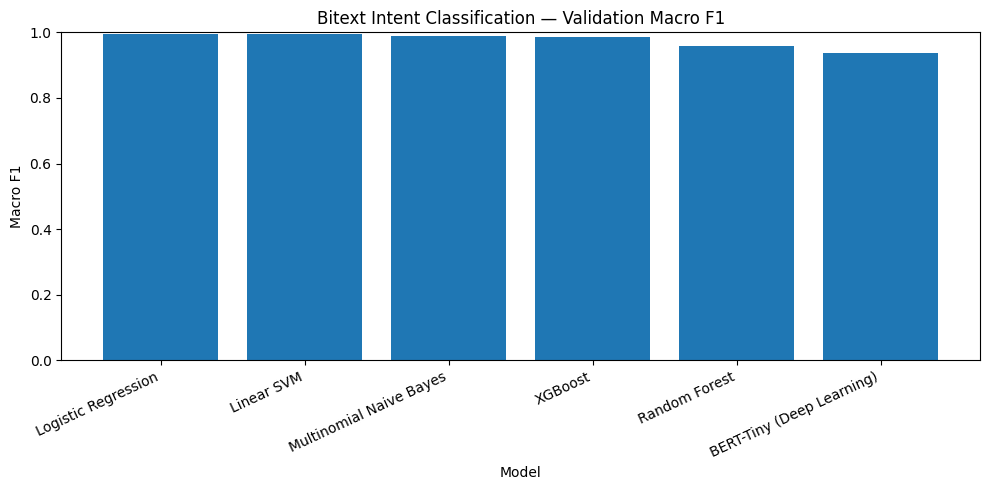


Best validation model: Logistic Regression
Comparison saved: d:\Data scientist\AI Customer Support Intelligence\reports\models\bitext_classical_vs_deep_learning.csv
Plot saved: d:\Data scientist\AI Customer Support Intelligence\reports\models\bitext_classical_vs_deep_learning.png

Important: Ye validation comparison hai. Official held-out test evaluation abhi baaki hai.


In [13]:
import json
import pandas as pd
import matplotlib.pyplot as plt

# Reports and model metadata
CLASSICAL_RESULTS_PATH = (
    ROOT / "reports" / "models" / "bitext_model_comparison.csv"
)

BERT_METADATA_PATH = (
    ROOT
    / "models"
    / "intent_classification"
    / "bert_tiny_bitext"
    / "training_metadata.json"
)

REPORT_DIR = ROOT / "reports" / "models"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not CLASSICAL_RESULTS_PATH.exists():
    raise FileNotFoundError(CLASSICAL_RESULTS_PATH)

if not BERT_METADATA_PATH.exists():
    raise FileNotFoundError(BERT_METADATA_PATH)

# Classical ML results
classical_df = pd.read_csv(CLASSICAL_RESULTS_PATH)

print("Classical ML models loaded:", len(classical_df))
display(classical_df)

# BERT validation metrics
with open(BERT_METADATA_PATH, "r", encoding="utf-8") as f:
    bert_metadata = json.load(f)

# Standardize comparison columns
comparison = classical_df[
    ["Model", "Accuracy", "Macro F1", "Weighted F1"]
].copy()

bert_row = pd.DataFrame([{
    "Model": "BERT-Tiny (Deep Learning)",
    "Accuracy": bert_metadata["best_validation_accuracy"],
    "Macro F1": bert_metadata["best_validation_macro_f1"],
    "Weighted F1": bert_metadata["best_validation_weighted_f1"],
}])

comparison = pd.concat(
    [comparison, bert_row],
    ignore_index=True,
)

comparison = comparison.sort_values(
    "Macro F1",
    ascending=False,
).reset_index(drop=True)

print("\n--- Overall Model Comparison ---")
display(comparison.round(4))

# Save comparison data
comparison_path = REPORT_DIR / "bitext_classical_vs_deep_learning.csv"
comparison.to_csv(comparison_path, index=False)

# Plot Macro F1
plt.figure(figsize=(10, 5))

plt.bar(
    comparison["Model"],
    comparison["Macro F1"],
)

plt.title("Bitext Intent Classification — Validation Macro F1")
plt.ylabel("Macro F1")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plot_path = REPORT_DIR / "bitext_classical_vs_deep_learning.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

best_model_name = comparison.iloc[0]["Model"]

print("\nBest validation model:", best_model_name)
print("Comparison saved:", comparison_path)
print("Plot saved:", plot_path)

print(
    "\nImportant: Ye validation comparison hai. "
    "Official held-out test evaluation abhi baaki hai."
)

In [14]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Original cleaned Bitext data se fresh split
final_df = df_dl.copy()

final_df["instruction_normalized"] = (
    final_df["instruction"].astype(str).str.strip().str.lower()
)

# Repeated normalized queries ko ek group banao
query_groups = (
    final_df.groupby("instruction_normalized", as_index=False)
    .agg(
        intent=("intent", "first"),
        category=("category", "first"),
    )
)

# Verify that each normalized query has a consistent label
assert (
    query_groups.groupby("instruction_normalized")["intent"].nunique().max() == 1
)
assert (
    query_groups.groupby("instruction_normalized")["category"].nunique().max() == 1
)

# First split: 70% train, 30% temporary
final_train_groups, temporary_groups = train_test_split(
    query_groups,
    test_size=0.30,
    random_state=2026,
    stratify=query_groups["intent"],
)

# Second split: temporary data equally into validation and test
final_val_groups, final_test_groups = train_test_split(
    temporary_groups,
    test_size=0.50,
    random_state=2026,
    stratify=temporary_groups["intent"],
)

train_queries_final = set(
    final_train_groups["instruction_normalized"]
)
val_queries_final = set(
    final_val_groups["instruction_normalized"]
)
test_queries_final = set(
    final_test_groups["instruction_normalized"]
)

# Assign ALL examples of each query to the same split
final_train_df = final_df[
    final_df["instruction_normalized"].isin(train_queries_final)
].copy()

final_val_df = final_df[
    final_df["instruction_normalized"].isin(val_queries_final)
].copy()

final_test_df = final_df[
    final_df["instruction_normalized"].isin(test_queries_final)
].copy()

# Verify no normalized query crosses split boundaries
train_val_overlap = train_queries_final & val_queries_final
train_test_overlap = train_queries_final & test_queries_final
val_test_overlap = val_queries_final & test_queries_final

assert not train_val_overlap
assert not train_test_overlap
assert not val_test_overlap

# Reuse the known 27 intent labels
final_train_df["label"] = label_encoder_dl.transform(
    final_train_df["intent"]
)
final_val_df["label"] = label_encoder_dl.transform(
    final_val_df["intent"]
)
final_test_df["label"] = label_encoder_dl.transform(
    final_test_df["intent"]
)

print("=== Fresh Final Split ===")
print("Train rows:", f"{len(final_train_df):,}")
print("Validation rows:", f"{len(final_val_df):,}")
print("Test rows:", f"{len(final_test_df):,}")

print("\nUnique query groups:")
print("Train:", len(train_queries_final))
print("Validation:", len(val_queries_final))
print("Test:", len(test_queries_final))

print("\nQuery overlap checks:")
print("Train vs validation:", len(train_val_overlap))
print("Train vs test:", len(train_test_overlap))
print("Validation vs test:", len(val_test_overlap))

print("\nIntent classes:")
print("Train:", final_train_df["intent"].nunique())
print("Validation:", final_val_df["intent"].nunique())
print("Test:", final_test_df["intent"].nunique())

print("\nTest set intent distribution:")
display(final_test_df["intent"].value_counts().sort_index())

print("\nAll query overlap checks passed.")

=== Fresh Final Split ===
Train rows: 18,843
Validation rows: 4,033
Test rows: 3,996

Unique query groups:
Train: 17059
Validation: 3656
Test: 3656

Query overlap checks:
Train vs validation: 0
Train vs test: 0
Validation vs test: 0

Intent classes:
Train: 27
Validation: 27
Test: 27

Test set intent distribution:


intent
cancel_order                143
change_order                150
change_shipping_address     146
check_cancellation_fee      145
check_invoice               146
check_payment_methods       149
check_refund_policy         149
complaint                   150
contact_customer_service    150
contact_human_agent         150
create_account              150
delete_account              149
delivery_options            152
delivery_period             149
edit_account                159
get_invoice                 138
get_refund                  147
newsletter_subscription     151
payment_issue               149
place_order                 150
recover_password            149
registration_problems       149
review                      149
set_up_shipping_address     150
switch_account              139
track_order                 151
track_refund                137
Name: count, dtype: int64


All query overlap checks passed.


In [15]:
import time
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# 1. Separate text and labels
X_train_final = final_train_df["instruction"].astype(str)
y_train_final = final_train_df["intent"].astype(str)

X_val_final = final_val_df["instruction"].astype(str)
y_val_final = final_val_df["intent"].astype(str)

print("Preparing TF-IDF features...")

# 2. Fit vectorizer ONLY on fresh training data
final_vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_features=40000,
    sublinear_tf=True,
    dtype=np.float32,
)

X_train_final_vec = final_vectorizer.fit_transform(X_train_final)
X_val_final_vec = final_vectorizer.transform(X_val_final)

print("Training matrix:", X_train_final_vec.shape)
print("Validation matrix:", X_val_final_vec.shape)
print("Vocabulary size:", len(final_vectorizer.vocabulary_))

# 3. Train Logistic Regression
final_lr_model = LogisticRegression(
    C=4.0,
    max_iter=1500,
    solver="lbfgs",
    random_state=42,
)

print("\nTraining Logistic Regression...")
start_time = time.time()

final_lr_model.fit(X_train_final_vec, y_train_final)

lr_training_seconds = time.time() - start_time

# 4. Evaluate on validation set
lr_val_predictions = final_lr_model.predict(X_val_final_vec)

lr_val_accuracy = accuracy_score(
    y_val_final,
    lr_val_predictions,
)

lr_val_macro_f1 = f1_score(
    y_val_final,
    lr_val_predictions,
    average="macro",
    zero_division=0,
)

lr_val_weighted_f1 = f1_score(
    y_val_final,
    lr_val_predictions,
    average="weighted",
    zero_division=0,
)

# 5. Display results
lr_fresh_results = {
    "Model": "Logistic Regression",
    "Validation Accuracy": lr_val_accuracy,
    "Validation Macro F1": lr_val_macro_f1,
    "Validation Weighted F1": lr_val_weighted_f1,
    "Training Time (seconds)": lr_training_seconds,
}

print("\n--- Fresh Split: Logistic Regression ---")
for key, value in lr_fresh_results.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nTest set abhi evaluate nahi kiya gaya hai.")

Preparing TF-IDF features...
Training matrix: (18843, 4904)
Validation matrix: (4033, 4904)
Vocabulary size: 4904

Training Logistic Regression...

--- Fresh Split: Logistic Regression ---
Model: Logistic Regression
Validation Accuracy: 0.9940
Validation Macro F1: 0.9940
Validation Weighted F1: 0.9941
Training Time (seconds): 3.4290

Test set abhi evaluate nahi kiya gaya hai.


In [16]:
import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader

# CPU-friendly settings
MAX_LENGTH_FINAL = 64
BATCH_SIZE_FINAL = 16

# Prepare the fresh training and validation text
X_train_dl_final = final_train_df["instruction"].astype(str).tolist()
y_train_dl_final = final_train_df["label"].to_numpy(dtype=np.int64)

X_val_dl_final = final_val_df["instruction"].astype(str).tolist()
y_val_dl_final = final_val_df["label"].to_numpy(dtype=np.int64)

print("Tokenizing fresh training split...")

train_encodings_final = tokenizer(
    X_train_dl_final,
    truncation=True,
    max_length=MAX_LENGTH_FINAL,
    padding=False,
)

print("Tokenizing fresh validation split...")

val_encodings_final = tokenizer(
    X_val_dl_final,
    truncation=True,
    max_length=MAX_LENGTH_FINAL,
    padding=False,
)


class FinalIntentDataset(Dataset):
    def __init__(self, encodings, labels):
        self.input_ids = encodings["input_ids"]
        self.attention_masks = encodings["attention_mask"]
        self.labels = np.asarray(labels, dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": torch.tensor(
                self.input_ids[index], dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                self.attention_masks[index], dtype=torch.long
            ),
            "labels": torch.tensor(
                self.labels[index], dtype=torch.long
            ),
        }


def collate_final_batch(batch):
    batch_size = len(batch)
    max_len = max(item["input_ids"].shape[0] for item in batch)

    input_ids = torch.full(
        (batch_size, max_len),
        tokenizer.pad_token_id,
        dtype=torch.long,
    )

    attention_mask = torch.zeros(
        (batch_size, max_len),
        dtype=torch.long,
    )

    labels = torch.empty(batch_size, dtype=torch.long)

    for i, item in enumerate(batch):
        length = item["input_ids"].shape[0]
        input_ids[i, :length] = item["input_ids"]
        attention_mask[i, :length] = item["attention_mask"]
        labels[i] = item["labels"]

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
    }


final_train_dataset = FinalIntentDataset(
    train_encodings_final,
    y_train_dl_final,
)

final_val_dataset = FinalIntentDataset(
    val_encodings_final,
    y_val_dl_final,
)

final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=BATCH_SIZE_FINAL,
    shuffle=True,
    collate_fn=collate_final_batch,
    num_workers=0,
)

final_val_loader = DataLoader(
    final_val_dataset,
    batch_size=BATCH_SIZE_FINAL,
    shuffle=False,
    collate_fn=collate_final_batch,
    num_workers=0,
)

# Verify one batch
sample_batch_final = next(iter(final_train_loader))

print("\n--- Fresh BERT Data Ready ---")
print("Training examples:", len(final_train_dataset))
print("Validation examples:", len(final_val_dataset))
print("Training batches:", len(final_train_loader))
print("Validation batches:", len(final_val_loader))
print("Input tensor shape:", tuple(sample_batch_final["input_ids"].shape))
print("Number of intents:", len(label_encoder_dl.classes_))
print("Device:", device)

Tokenizing fresh training split...
Tokenizing fresh validation split...

--- Fresh BERT Data Ready ---
Training examples: 18843
Validation examples: 4033
Training batches: 1178
Validation batches: 253
Input tensor shape: (16, 14)
Number of intents: 27
Device: cpu


In [17]:
import copy
import time
import torch
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from transformers import BertForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

torch.set_num_threads(min(4, __import__("os").cpu_count() or 1))

# Initialize a FRESH model from pretrained base weights.
# This does not load the previous fine-tuned checkpoint.
print("Initializing a fresh BERT-Tiny classifier...")

fresh_model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_encoder_dl.classes_),
    label2id=label2id,
    id2label=id2label,
    problem_type="single_label_classification",
)

fresh_model = fresh_model.to(device)

# Fine-tuning configuration
FRESH_EPOCHS = 3
FRESH_LEARNING_RATE = 2e-5
FRESH_WEIGHT_DECAY = 0.01

fresh_optimizer = torch.optim.AdamW(
    fresh_model.parameters(),
    lr=FRESH_LEARNING_RATE,
    weight_decay=FRESH_WEIGHT_DECAY,
)

fresh_epoch_results = []
best_fresh_macro_f1 = -1.0
best_fresh_epoch = 0
best_fresh_state = None

print("Device:", device)
print("Training rows:", len(final_train_dataset))
print("Validation rows:", len(final_val_dataset))
print("Epochs:", FRESH_EPOCHS)
print("Batches per epoch:", len(final_train_loader))

overall_start = time.time()

for epoch in range(FRESH_EPOCHS):
    fresh_model.train()
    losses = []

    progress = tqdm(
        final_train_loader,
        desc=f"Fresh BERT Epoch {epoch + 1}/{FRESH_EPOCHS}",
    )

    for batch in progress:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        fresh_optimizer.zero_grad(set_to_none=True)

        outputs = fresh_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            fresh_model.parameters(),
            max_norm=1.0,
        )

        fresh_optimizer.step()

        loss_value = float(loss.detach().cpu())
        losses.append(loss_value)

        progress.set_postfix(
            loss=f"{loss_value:.4f}",
            avg_loss=f"{np.mean(losses):.4f}",
        )

    # Validation
    fresh_model.eval()
    val_predictions = []
    val_true_labels = []

    with torch.no_grad():
        for batch in tqdm(
            final_val_loader,
            desc="Validation",
            leave=False,
        ):
            outputs = fresh_model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device),
            )

            val_predictions.extend(
                outputs.logits.argmax(dim=-1).cpu().tolist()
            )
            val_true_labels.extend(batch["labels"].tolist())

    accuracy = accuracy_score(val_true_labels, val_predictions)

    macro_f1 = f1_score(
        val_true_labels,
        val_predictions,
        average="macro",
        zero_division=0,
    )

    weighted_f1 = f1_score(
        val_true_labels,
        val_predictions,
        average="weighted",
        zero_division=0,
    )

    row = {
        "epoch": epoch + 1,
        "train_loss": float(np.mean(losses)),
        "validation_accuracy": float(accuracy),
        "validation_macro_f1": float(macro_f1),
        "validation_weighted_f1": float(weighted_f1),
    }

    fresh_epoch_results.append(row)

    # Save the best epoch in memory using validation Macro F1
    if macro_f1 > best_fresh_macro_f1:
        best_fresh_macro_f1 = macro_f1
        best_fresh_epoch = epoch + 1
        best_fresh_state = copy.deepcopy(fresh_model.state_dict())

    print(f"\nEpoch {epoch + 1} results")
    print(f"Training loss: {row['train_loss']:.4f}")
    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")
    print(f"Validation Weighted F1: {weighted_f1:.4f}")
    print("Best epoch so far:", best_fresh_epoch)

# Restore best validation checkpoint
fresh_model.load_state_dict(best_fresh_state)
fresh_model.eval()

fresh_training_seconds = time.time() - overall_start

print("\n--- Fresh BERT Training Complete ---")
print("Best epoch:", best_fresh_epoch)
print(f"Best validation Macro F1: {best_fresh_macro_f1:.4f}")
print(f"Total time: {fresh_training_seconds / 60:.2f} minutes")

print("\nEpoch comparison:")
display(pd.DataFrame(fresh_epoch_results).round(4))

Initializing a fresh BERT-Tiny classifier...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were 

Device: cpu
Training rows: 18843
Validation rows: 4033
Epochs: 3
Batches per epoch: 1178


Fresh BERT Epoch 1/3:   0%|          | 0/1178 [00:00<?, ?it/s]

Validation:   0%|          | 0/253 [00:00<?, ?it/s]

... (4 outputs left out)

Fresh BERT Epoch 3/3:   0%|          | 0/1178 [00:00<?, ?it/s]

Validation:   0%|          | 0/253 [00:00<?, ?it/s]


Epoch 3 results
Training loss: 1.2132
Validation accuracy: 0.9417
Validation Macro F1: 0.9423
Validation Weighted F1: 0.9418
Best epoch so far: 3

--- Fresh BERT Training Complete ---
Best epoch: 3
Best validation Macro F1: 0.9423
Total time: 6.03 minutes

Epoch comparison:


,epoch,train_loss,validation_accuracy,validation_macro_f1,validation_weighted_f1
0,1,2.9130,0.6672,0.6393,0.6369
1,2,1.9693,0.8681,0.8673,0.8666
2,3,1.2132,0.9417,0.9423,0.9418


In [18]:
import json
import pandas as pd
from pathlib import Path

# Dedicated folder for the fresh-split model
FINAL_BERT_DIR = (
    ROOT
    / "models"
    / "intent_classification"
    / "bert_tiny_bitext_final_split"
)

REPORT_DIR = ROOT / "reports" / "models"

FINAL_BERT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Cell 15 already restored the best validation checkpoint
fresh_model.eval()

# Save model and tokenizer
fresh_model.save_pretrained(FINAL_BERT_DIR)
tokenizer.save_pretrained(FINAL_BERT_DIR)

# Save label mapping
label_mapping_final = {
    "label2id": {
        str(label): int(index)
        for label, index in label2id.items()
    },
    "id2label": {
        str(index): str(label)
        for index, label in id2label.items()
    },
}

with open(
    FINAL_BERT_DIR / "label_mapping.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(label_mapping_final, f, indent=2, ensure_ascii=False)

# Save training metadata
best_row = max(
    fresh_epoch_results,
    key=lambda row: row["validation_macro_f1"],
)

metadata_final = {
    "model_name": MODEL_NAME,
    "model_type": "BERT-Tiny sequence classifier",
    "split_seed": 2026,
    "training_rows": int(len(final_train_df)),
    "validation_rows": int(len(final_val_df)),
    "test_rows": int(len(final_test_df)),
    "query_overlap": 0,
    "epochs_completed": int(len(fresh_epoch_results)),
    "best_epoch": int(best_row["epoch"]),
    "validation_accuracy": float(best_row["validation_accuracy"]),
    "validation_macro_f1": float(best_row["validation_macro_f1"]),
    "validation_weighted_f1": float(best_row["validation_weighted_f1"]),
    "max_sequence_length": int(MAX_LENGTH_FINAL),
    "batch_size": int(BATCH_SIZE_FINAL),
    "device": str(device),
    "training_time_seconds": round(fresh_training_seconds, 2),
    "note": "Final test set has not yet been evaluated.",
}

with open(
    FINAL_BERT_DIR / "training_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(metadata_final, f, indent=2, ensure_ascii=False)

# Save epoch history
history_path = REPORT_DIR / "bert_tiny_final_split_history.csv"

pd.DataFrame(fresh_epoch_results).to_csv(
    history_path,
    index=False,
)

print("Fresh BERT checkpoint saved!")
print("Model folder:", FINAL_BERT_DIR)
print("Best epoch:", metadata_final["best_epoch"])
print("Validation Accuracy:", round(metadata_final["validation_accuracy"], 4))
print("Validation Macro F1:", round(metadata_final["validation_macro_f1"], 4))
print("Training history:", history_path)

print("\nSaved files:")
for path in sorted(FINAL_BERT_DIR.iterdir()):
    print(f"{path.name} — {path.stat().st_size / 1024:.1f} KB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fresh BERT checkpoint saved!
Model folder: d:\Data scientist\AI Customer Support Intelligence\models\intent_classification\bert_tiny_bitext_final_split
Best epoch: 3
Validation Accuracy: 0.9417
Validation Macro F1: 0.9423
Training history: d:\Data scientist\AI Customer Support Intelligence\reports\models\bert_tiny_final_split_history.csv

Saved files:
config.json — 2.3 KB
label_mapping.json — 1.6 KB
model.safetensors — 17150.6 KB
tokenizer_config.json — 1.4 KB
training_metadata.json — 0.6 KB
vocab.txt — 255.9 KB


In [19]:
import json
import time
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# --------------------------------------------------
# 1. Prepare the untouched test set
# --------------------------------------------------
X_test_final = final_test_df["instruction"].astype(str)
y_test_final = final_test_df["intent"].astype(str)

# Logistic Regression: transform with training-only vectorizer
X_test_final_vec = final_vectorizer.transform(X_test_final)

print("Test records:", len(final_test_df))
print("Test classes:", y_test_final.nunique())
print("TF-IDF test matrix:", X_test_final_vec.shape)

# --------------------------------------------------
# 2. Evaluate Logistic Regression
# --------------------------------------------------
print("\nEvaluating Logistic Regression...")

lr_test_predictions = final_lr_model.predict(X_test_final_vec)

lr_test_metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test_final, lr_test_predictions),
    "Macro F1": f1_score(
        y_test_final,
        lr_test_predictions,
        average="macro",
        zero_division=0,
    ),
    "Weighted F1": f1_score(
        y_test_final,
        lr_test_predictions,
        average="weighted",
        zero_division=0,
    ),
}

# --------------------------------------------------
# 3. Tokenize test examples for BERT
# --------------------------------------------------
print("Tokenizing test data for BERT...")

test_encodings_final = tokenizer(
    X_test_final.tolist(),
    truncation=True,
    max_length=MAX_LENGTH_FINAL,
    padding=False,
)

test_dataset_final = FinalIntentDataset(
    test_encodings_final,
    final_test_df["label"].to_numpy(dtype=np.int64),
)

test_loader_final = DataLoader(
    test_dataset_final,
    batch_size=BATCH_SIZE_FINAL,
    shuffle=False,
    collate_fn=collate_final_batch,
    num_workers=0,
)

# --------------------------------------------------
# 4. Evaluate the best BERT checkpoint
# --------------------------------------------------
print("Evaluating BERT-Tiny...")

fresh_model.eval()
bert_test_predictions_encoded = []
bert_test_true_labels = []

start_time = time.time()

with torch.no_grad():
    for batch in test_loader_final:
        outputs = fresh_model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
        )

        predictions = outputs.logits.argmax(dim=-1)

        bert_test_predictions_encoded.extend(
            predictions.cpu().numpy().tolist()
        )
        bert_test_true_labels.extend(
            batch["labels"].numpy().tolist()
        )

bert_test_seconds = time.time() - start_time

# Convert class IDs back to intent names
bert_test_predictions = label_encoder_dl.inverse_transform(
    np.asarray(bert_test_predictions_encoded, dtype=np.int64)
)

bert_test_true_intents = label_encoder_dl.inverse_transform(
    np.asarray(bert_test_true_labels, dtype=np.int64)
)

bert_test_metrics = {
    "Model": "BERT-Tiny",
    "Accuracy": accuracy_score(
        bert_test_true_intents,
        bert_test_predictions,
    ),
    "Macro F1": f1_score(
        bert_test_true_intents,
        bert_test_predictions,
        average="macro",
        zero_division=0,
    ),
    "Weighted F1": f1_score(
        bert_test_true_intents,
        bert_test_predictions,
        average="weighted",
        zero_division=0,
    ),
}

# --------------------------------------------------
# 5. Display the same-test-set comparison
# --------------------------------------------------
final_test_comparison = pd.DataFrame([
    lr_test_metrics,
    bert_test_metrics,
])

final_test_comparison = final_test_comparison.sort_values(
    "Macro F1",
    ascending=False,
).reset_index(drop=True)

print("\n=== FINAL TEST-SET RESULTS ===")
display(final_test_comparison.round(4))

print(f"BERT test inference time: {bert_test_seconds:.2f} seconds")

# --------------------------------------------------
# 6. Save the final comparison report
# --------------------------------------------------
REPORT_DIR = ROOT / "reports" / "models"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = (
    REPORT_DIR / "bitext_final_test_comparison.csv"
)
metrics_path = (
    REPORT_DIR / "bitext_final_test_metrics.json"
)

final_test_comparison.to_csv(comparison_path, index=False)

metrics_data = {
    "test_samples": int(len(final_test_df)),
    "intent_classes": int(y_test_final.nunique()),
    "query_overlap_train_test": 0,
    "query_overlap_validation_test": 0,
    "results": [
        {
            key: (
                float(value)
                if isinstance(value, (np.floating, float))
                else value
            )
            for key, value in row.items()
        }
        for row in final_test_comparison.to_dict(orient="records")
    ],
    "bert_test_inference_seconds": round(bert_test_seconds, 2),
    "note": (
        "Both models were trained using the same final training split "
        "and evaluated on the same untouched test set. "
        "Results describe performance on this dataset and do not "
        "guarantee real-world customer-support performance."
    ),
}

with metrics_path.open("w", encoding="utf-8") as f:
    json.dump(metrics_data, f, indent=2, ensure_ascii=False)

print("\nComparison CSV:", comparison_path)
print("Metrics JSON:", metrics_path)

Test records: 3996
Test classes: 27
TF-IDF test matrix: (3996, 4904)

Evaluating Logistic Regression...
Tokenizing test data for BERT...
Evaluating BERT-Tiny...

=== FINAL TEST-SET RESULTS ===


,Model,Accuracy,Macro F1,Weighted F1
0,Logistic Regression,0.9932,0.9932,0.9933
1,BERT-Tiny,0.9437,0.9431,0.9439


BERT test inference time: 2.23 seconds

Comparison CSV: d:\Data scientist\AI Customer Support Intelligence\reports\models\bitext_final_test_comparison.csv
Metrics JSON: d:\Data scientist\AI Customer Support Intelligence\reports\models\bitext_final_test_metrics.json


In [20]:
import json
import joblib
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

# Output directories
MODEL_DIR = ROOT / "models" / "intent_classification"
REPORT_DIR = ROOT / "reports" / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Verify the final selected model and its fitted vectorizer
assert final_lr_model is not None
assert final_vectorizer is not None
assert hasattr(final_lr_model, "predict_proba")

# Build intent-to-category mapping from the dataset
intent_to_categories_final = (
    df_dl.groupby("intent")["category"]
    .agg(lambda values: sorted(set(values)))
    .to_dict()
)

# Package everything required for inference
final_artifact = {
    "model": final_lr_model,
    "vectorizer": final_vectorizer,
    "model_name": "Logistic Regression",
    "classes": final_lr_model.classes_.tolist(),
    "intent_to_categories": intent_to_categories_final,
    "input_column": "instruction",
    "target_column": "intent",
    "vectorizer_config": {
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_features": 40000,
        "sublinear_tf": True,
    },
}

# Save to a new file; preserve the earlier artifact
final_model_path = (
    MODEL_DIR / "bitext_intent_model_final.joblib"
)

joblib.dump(final_artifact, final_model_path, compress=3)

# Save final test results
final_metrics = {
    "selected_model": "Logistic Regression",
    "test_accuracy": float(
        accuracy_score(y_test_final, lr_test_predictions)
    ),
    "test_macro_f1": float(
        f1_score(
            y_test_final,
            lr_test_predictions,
            average="macro",
            zero_division=0,
        )
    ),
    "test_weighted_f1": float(
        f1_score(
            y_test_final,
            lr_test_predictions,
            average="weighted",
            zero_division=0,
        )
    ),
    "test_records": int(len(y_test_final)),
    "intent_classes": int(y_test_final.nunique()),
    "train_records": int(len(final_train_df)),
    "validation_records": int(len(final_val_df)),
    "query_overlap_train_test": 0,
    "query_overlap_validation_test": 0,
    "saved_at_utc": datetime.now(timezone.utc).isoformat(),
    "note": (
        "Evaluated on the untouched query-grouped test split. "
        "Real-world performance is not guaranteed by this dataset result."
    ),
}

metrics_path = REPORT_DIR / "bitext_selected_model_metrics.json"

with metrics_path.open("w", encoding="utf-8") as f:
    json.dump(final_metrics, f, indent=2, ensure_ascii=False)

# Save model comparison alongside the selected artifact
final_test_comparison.to_csv(
    REPORT_DIR / "bitext_final_test_comparison.csv",
    index=False,
)

print("Final deployment model saved!")
print("Model path:", final_model_path)
print("Model size (MB):", round(final_model_path.stat().st_size / (1024 ** 2), 2))

print("\nFinal test metrics:")
print(json.dumps(final_metrics, indent=2))

print("\nComparison report:")
print(REPORT_DIR / "bitext_final_test_comparison.csv")

Final deployment model saved!
Model path: d:\Data scientist\AI Customer Support Intelligence\models\intent_classification\bitext_intent_model_final.joblib
Model size (MB): 0.96

Final test metrics:
{
  "selected_model": "Logistic Regression",
  "test_accuracy": 0.9932432432432432,
  "test_macro_f1": 0.9932489589675852,
  "test_weighted_f1": 0.9932523380645804,
  "test_records": 3996,
  "intent_classes": 27,
  "train_records": 18843,
  "validation_records": 4033,
  "query_overlap_train_test": 0,
  "query_overlap_validation_test": 0,
  "saved_at_utc": "2026-10-25T04:58:33.101011+00:00",
  "note": "Evaluated on the untouched query-grouped test split. Real-world performance is not guaranteed by this dataset result."
}

Comparison report:
d:\Data scientist\AI Customer Support Intelligence\reports\models\bitext_final_test_comparison.csv


In [21]:
import joblib
import pandas as pd
import json

# Final saved artifact path
FINAL_MODEL_PATH = (
    ROOT
    / "models"
    / "intent_classification"
    / "bitext_intent_model_final.joblib"
)

if not FINAL_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Final model file not found: {FINAL_MODEL_PATH}"
    )

# Load artifact from disk
artifact_check = joblib.load(FINAL_MODEL_PATH)

loaded_lr = artifact_check["model"]
loaded_tfidf = artifact_check["vectorizer"]
intent_to_categories_check = artifact_check["intent_to_categories"]

print("Saved model loaded successfully!")
print("Model:", artifact_check["model_name"])
print("Model size (MB):", round(
    FINAL_MODEL_PATH.stat().st_size / (1024 ** 2), 2
))
print("Known intents:", len(artifact_check["classes"]))


def predict_intent_final(message):
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please enter a non-empty customer message.")

    features = loaded_tfidf.transform([message.strip()])

    probabilities = loaded_lr.predict_proba(features)[0]
    best_index = int(probabilities.argmax())

    intent = str(loaded_lr.classes_[best_index])
    categories = intent_to_categories_check.get(intent, [])

    return {
        "customer_message": message,
        "predicted_intent": intent,
        "category": categories[0] if len(categories) == 1 else categories,
        "model_score": round(float(probabilities[best_index]), 4),
    }


# Smoke tests
test_messages = [
    "I want to cancel my order",
    "My refund has not arrived yet",
    "I forgot my password and cannot log in",
    "Can you send me a copy of my invoice?",
    "I want to change my shipping address",
]

smoke_test_results = pd.DataFrame(
    predict_intent_final(message)
    for message in test_messages
)

display(smoke_test_results)

# Save smoke-test results
smoke_test_path = (
    ROOT / "reports" / "models"
    / "bitext_final_model_smoke_test.csv"
)

smoke_test_path.parent.mkdir(parents=True, exist_ok=True)
smoke_test_results.to_csv(smoke_test_path, index=False)

print("\nSmoke-test results saved to:", smoke_test_path)

Saved model loaded successfully!
Model: Logistic Regression
Model size (MB): 0.96
Known intents: 27


,customer_message,predicted_intent,category,model_score
0,I want to cancel my order,cancel_order,ORDER,0.5911
1,My refund has not arrived yet,track_refund,REFUND,0.3424
2,I forgot my password and cannot log in,recover_password,ACCOUNT,0.7897
3,Can you send me a copy of my invoice?,get_invoice,INVOICE,0.6959
4,I want to change my shipping address,change_shipping_address,SHIPPING,0.9874



Smoke-test results saved to: d:\Data scientist\AI Customer Support Intelligence\reports\models\bitext_final_model_smoke_test.csv
